In [166]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import torchvision.transforms.v2 as v2
from torchvision.transforms.v2 import functional as F
from torchvision.utils import save_image
from torchvision.io import read_image
import robomimic.utils.file_utils as FileUtils
import robomimic.utils.torch_utils as TorchUtils

In [80]:
def show(*imgs):
    import matplotlib.pyplot as plt
    fix, axs = plt.subplots(ncols=len(imgs), squeeze=False)
    for i, img in enumerate(imgs):
        if isinstance(img, torch.Tensor):
            img = img.detach()
            img = F.to_pil_image(img)
        axs[0, i].imshow(np.asarray(img))
        axs[0, i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

In [8]:
ckpt_path = '/home/smlr_g2/smlr_g2_SS_26/diffusion_robert/ss26_g2_smlr/sim2real/models/ep_520_Square_RealWorldDeployment.pth'
algo_name, ckpt_dict = FileUtils.algo_name_from_checkpoint(ckpt_path=ckpt_path)
device = TorchUtils.get_torch_device(try_to_use_cuda=True)
policy, ckpt_dict = FileUtils.policy_from_checkpoint(ckpt_dict=ckpt_dict, device=device, verbose=True)

============= Loaded Config =============
{
    "algo_name": "diffusion_policy",
    "experiment": {
        "name": "dp_augmented_5k",
        "validate": true,
        "logging": {
            "terminal_output_to_txt": true,
            "log_tb": true,
            "log_wandb": false,
            "wandb_proj_name": "debug"
        },
        "save": {
            "enabled": true,
            "every_n_seconds": null,
            "every_n_epochs": 10,
            "epochs": [],
            "on_best_validation": true,
            "on_best_rollout_return": true,
            "on_best_rollout_success_rate": true
        },
        "epoch_every_n_steps": 2000,
        "validation_epoch_every_n_steps": 100,
        "env": null,
        "additional_envs": null,
        "render": false,
        "render_video": false,
        "keep_all_videos": false,
        "video_skip": 5,
        "rollout": {
            "enabled": true,
            "n": 30,
            "horizon": 200,
            "rate": 20,

/home/smlr_g2/anaconda3/envs/dynaguide_robert/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/smlr_g2/anaconda3/envs/dynaguide_robert/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


number of parameters: 6.914689e+07
============= Loaded Policy =============
DiffusionPolicyUNet (
  ModuleDict(
    (policy): ModuleDict(
      (obs_encoder): ObservationGroupEncoder(
          group=obs
          ObservationEncoder(
              Key(
                  name=agentview_image
                  shape=[3, 84, 84]
                  modality=rgb
                  randomizer=OpticalAugmentationForDynaguide(input_shape=[3, 84, 84], crop_size=[76, 76], num_samples=1)
                  net=VisualCore(
                    input_shape=[3, 76, 76]
                    output_shape=[64]
                    backbone_net=ResNet18Conv(input_channel=3, input_coord_conv=False)
                    pool_net=SpatialSoftmax(num_kp=32, temperature=1.0, noise=0.0)
                  )
                  sharing_from=None
              )
              Key(
                  name=robot0_eef_pos
                  shape=[3]
                  modality=low_dim
                  randomizer=None
       

In [10]:
sim_obs = torch.load('/home/smlr_g2/smlr_g2_SS_26/diffusion_robert/ss26_g2_smlr/sim2real/dataset_inspect/sim_obs.pt')
real_obs = torch.load('/home/smlr_g2/smlr_g2_SS_26/diffusion_robert/ss26_g2_smlr/sim2real/dataset_inspect/real_obs.pt')

In [14]:
sim_obs['robot0_eef_pos']

array([[-0.10831837, -0.01377308,  1.01205572],
       [-0.10831837, -0.01377308,  1.01205572]])

In [52]:
policy.start_episode()
policy(ob=sim_obs)

array([-0.19263633, -0.23063016, -0.03074578,  0.01980488, -0.03158121,
       -0.01837129, -0.9984265 ])

In [61]:
policy.start_episode()
policy(ob=real_obs)

array([ 0.53418022,  0.46238998,  0.20624603, -0.21409653,  0.24938731,
        0.17060734,  1.        ])

In [88]:
sim_agent_image = torch.as_tensor(sim_obs['agentview_image'][0])
real_agent_image = torch.as_tensor(real_obs['agentview_image'][0])
sim_hand_image = torch.as_tensor(sim_obs['robot0_eye_in_hand_image'][0])
real_hand_image = torch.as_tensor(real_obs['robot0_eye_in_hand_image'][0])

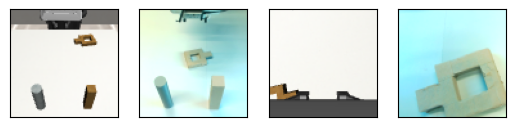

In [ ]:
show(sim_agent_image, rea    

In [149]:
save_image(sim_hand_image, 'sim_hand_image.png')

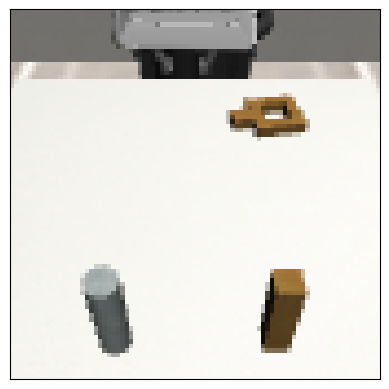

In [90]:
show(sim_agent_image)

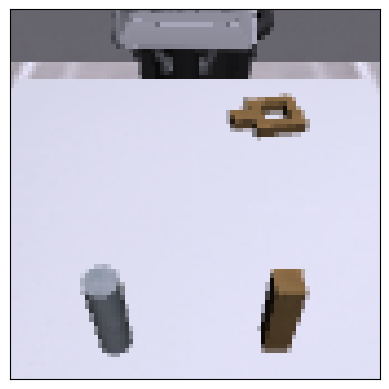

In [98]:
show(F.adjust_saturation(sim_agent_image, 0.8) * torch.tensor((.9, .9, 1.))[:, None, None])

In [113]:
save_image(real_agent_image.float() / 255.0, 'real_agent_image.png')

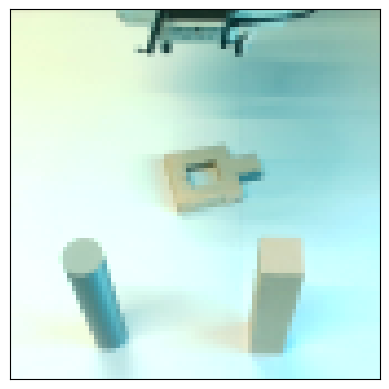

In [112]:
show(real_agent_image.float() / 255.0)

In [ ]:
show()

In [100]:
real_obs['agentview_image']

tensor([[[[232, 233, 233,  ..., 139, 142, 145],
          [238, 238, 238,  ..., 140, 144, 146],
          [241, 241, 239,  ..., 149, 151, 152],
          ...,
          [242, 244, 242,  ..., 208, 208, 208],
          [242, 244, 242,  ..., 208, 208, 207],
          [242, 244, 242,  ..., 208, 210, 208]],

         [[239, 240, 241,  ..., 173, 173, 174],
          [247, 247, 247,  ..., 176, 176, 177],
          [249, 250, 251,  ..., 184, 184, 185],
          ...,
          [255, 255, 255,  ..., 255, 255, 255],
          [255, 255, 255,  ..., 255, 255, 255],
          [255, 255, 255,  ..., 255, 255, 255]],

         [[206, 207, 206,  ..., 156, 154, 155],
          [213, 213, 213,  ..., 158, 157, 157],
          [213, 213, 212,  ..., 164, 163, 164],
          ...,
          [255, 255, 255,  ..., 255, 255, 255],
          [255, 255, 255,  ..., 255, 255, 255],
          [255, 255, 255,  ..., 255, 255, 255]]],


        [[[232, 233, 233,  ..., 139, 142, 145],
          [238, 238, 238,  ..., 140

In [120]:
agent_image_edited = read_image('/home/smlr_g2/smlr_g2_SS_26/diffusion_robert/ss26_g2_smlr/real_agent_image_edited.png').float() / 255.0

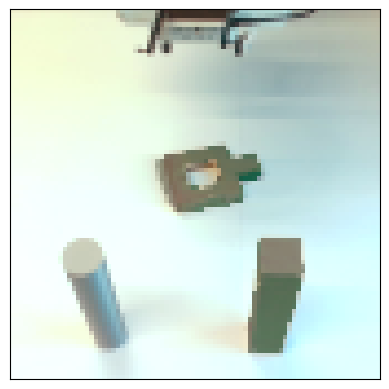

In [121]:
show(agent_image_edited)

In [122]:
agent_image_og = real_agent_image.float() / 255.0

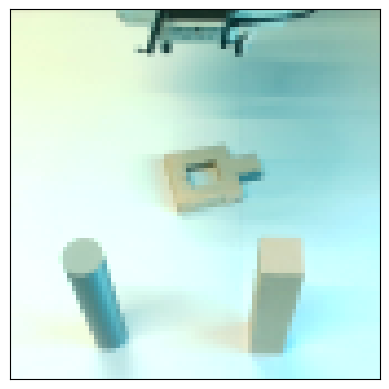

In [123]:
torch(agent_image_og.flatten(1, 2).T, agent_image_edited.flatten(1, 2).T)

In [126]:
T = torch.linalg.lstsq(agent_image_og.flatten(1, 2).T, agent_image_edited.flatten(1, 2).T).solution

In [132]:
agent_image_og.flatten(1, 2).T.shape

torch.Size([7056, 3])

In [135]:
agent_image_og.shape

torch.Size([3, 84, 84])

In [138]:
agent_image_corrected = torch.clamp(torch.einsum('chw, ck->khw', agent_image_og, T), 0., 1.)

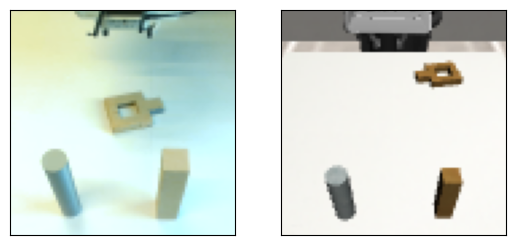

In [146]:
show(F.adjust_saturation(agent_image_corrected, 1.5), sim_agent_image)

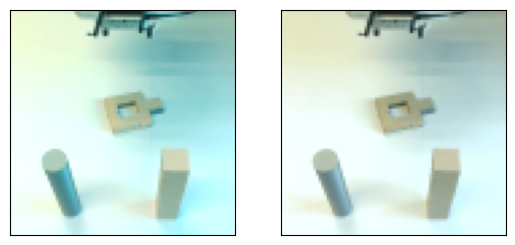

In [139]:
show(agent_image_og, agent_image_corrected)

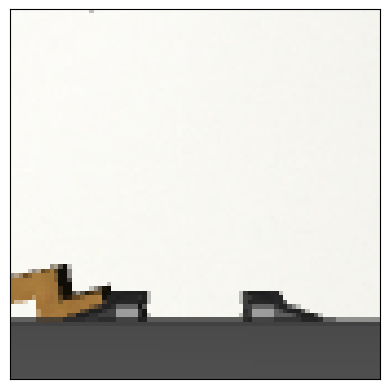

In [150]:
show(sim_hand_image)

In [154]:
sim_hand_overlay = read_image('/home/smlr_g2/smlr_g2_SS_26/diffusion_robert/ss26_g2_smlr/sim_hand_overlay.png', mode='RGBA')

AttributeError: 'str' object has no attribute 'value'

In [153]:
sim_hand_overlay

tensor([[[ 0,  0,  0,  ...,  0,  0,  0],
         [ 0,  0,  0,  ...,  0,  0,  0],
         [ 0,  0,  0,  ...,  0,  0,  0],
         ...,
         [47, 47, 47,  ..., 47, 47, 47],
         [47, 47, 47,  ..., 47, 47, 47],
         [86, 86, 86,  ..., 47, 47, 47]]], dtype=torch.uint8)

In [155]:
from PIL import Image

In [195]:
sim_hand_overlay = Image.open('/home/smlr_g2/smlr_g2_SS_26/diffusion_robert/ss26_g2_smlr/sim_hand_overlay.png').convert('RGBA')

In [196]:
sim_hand_overlay = torch.tensor(np.asarray(sim_hand_overlay)).movedim(-1, -3) / 255.0

In [197]:
sim_hand_overlay[3] = sim_hand_overlay[3] >= .95

In [203]:
sim_hand_overlay.shape

torch.Size([4, 84, 84])

In [204]:
torch.save(sim_hand_overlay, '/home/smlr_g2/smlr_g2_SS_26/diffusion_robert/ss26_g2_smlr/sim2real/dataset_inspect/sim_hand_overlay.pt')